## 1. Introduction

Exploratory Data Analysis (EDA) is an important step in the data analysis process. It helps us understand datasets, identify patterns, detect anomalies, and discover relationships between variables.
In this project, we will perform EDA on the Student Performance dataset, which contains demographic information, educational background, and examination scores of students across three subjects: Mathematics, Reading, and Writing.
We will use Python libraries such as Pandas, NumPy, Matplotlib, and Seaborn to explore, analyse, and visualize the dataset.

## 2. Business Problem Statement

We have been provided with a Student Performance dataset containing students' Maths, Reading and Writing scores, along with additional demographic and educational information.
The objective of this project is to analyse students' academic performance and investigate how different categorical variables are associated with their scores across all three subjects.
We will also examine the distribution and variability of subject scores, identify potential outliers, and investigate relationships between the three subjects.
The final goal is to extract meaningful, data-driven insights and present conclusions about the patterns observed in student performance, without making unsupported causal claims.

## 3. Project Objectives

1. Understand the structure and characteristics of the Student Performance dataset.
2. Identify missing values, duplicate records, inconsistencies, and potential outliers.
3. Investigate associations between categorical variables and students' academic scores.
4. Analyse the distribution and variability of Maths, Reading, and Writing scores.
5. Examine correlations and relationships among the three subject scores.
6. Create meaningful visualizations to communicate analytical findings.
7. Summarize key insights and provide evidence-based conclusions.

## 4. Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## 5. Loading the Dataset

In [2]:
df = pd.read_csv("datasets/StudentsPerformance.csv")

In [3]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


## 6. Data Understanding

In [4]:
# Dataset dimensions — rows and columns.
df.shape

(1000, 8)

In [5]:
# Column names.
df.columns

Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='str')

In [6]:
# Find out which data type Pandas has assigned to each column.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 103.5 KB


- Dataset contains 1000 rows and 8 columns.
- 3 numerical columns and 5 categorical columns.
- All numerical columns have int64 data type.
- All categorical columns have str data type.
- No missing values are indicated by the non-null counts.

In [7]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


## 7. Data Cleaning

In [8]:
df.duplicated().sum()

# No duplicate records were found

np.int64(0)

In [9]:
df.isnull().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

In [10]:
df[df['math score'] == 0]

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
59,female,group C,some high school,free/reduced,none,0,17,10


## 8. Exploratory Data Analysis

### 8.1 Bivariate Analysis

In [11]:
# Business question: Is gender associated with differences in average Maths, Reading, and Writing scores?

df.groupby('gender')[['math score','reading score','writing score']].mean()

,math score,reading score,writing score
gender,,,
female,63.633205,72.608108,72.467181
male,68.728216,65.473029,63.311203


In [12]:
# Task: Calculate the number of Female and Male students.

df['gender'].value_counts()


gender
female    518
male      482
Name: count, dtype: int64

In [13]:
df.groupby('gender')[['math score','reading score','writing score']].std()

,math score,reading score,writing score
gender,,,
female,15.491453,14.378245,14.844842
male,14.356277,13.931832,14.113832


In [14]:
df.groupby('gender')[['math score','reading score','writing score']].median()

,math score,reading score,writing score
gender,,,
female,65.0,73.0,74.0
male,69.0,66.0,64.0


- Female students have higher average Reading and Writing scores.

- Male students have a higher average Maths scores

- Writing has the largest mean-score gap (approximately 9.16 marks).

- Female students have higher standard deviations in all three subjects.

- Median comparisons show the same direction as mean comparisons.

In [15]:
df.groupby('lunch')[['math score','reading score','writing score']].mean()

,math score,reading score,writing score
lunch,,,
free/reduced,58.921127,64.653521,63.022535
standard,70.034109,71.654264,70.823256


In [16]:
df['lunch'].value_counts()

lunch
standard        645
free/reduced    355
Name: count, dtype: int64

In [17]:
df.groupby('lunch')[['math score','reading score','writing score']].std()

,math score,reading score,writing score
lunch,,,
free/reduced,15.159956,14.895339,15.433823
standard,13.653501,13.830602,14.339487


In [18]:
df.groupby('lunch')[['math score','reading score','writing score']].median()

,math score,reading score,writing score
lunch,,,
free/reduced,60.0,65.0,64.0
standard,69.0,72.0,72.0


In [19]:
df['test preparation course'].value_counts()

test preparation course
none         642
completed    358
Name: count, dtype: int64

In [20]:
df.groupby('test preparation course')[['math score','reading score','writing score']].mean()

,math score,reading score,writing score
test preparation course,,,
completed,69.695531,73.893855,74.418994
none,64.077882,66.534268,64.504673


In [21]:
df.groupby('test preparation course')[['math score','reading score','writing score']].median()

,math score,reading score,writing score
test preparation course,,,
completed,69.0,75.0,76.0
none,64.0,67.0,65.0


In [22]:
df.groupby('test preparation course')[['math score','reading score','writing score']].std()

,math score,reading score,writing score
test preparation course,,,
completed,14.444699,13.638384,13.375335
none,15.192376,14.463885,14.999661


In [23]:
df['parental level of education'].value_counts()

parental level of education
some college          226
associate's degree    222
high school           196
some high school      179
bachelor's degree     118
master's degree        59
Name: count, dtype: int64

In [24]:
df.groupby('parental level of education')[['math score','reading score','writing score']].mean()

,math score,reading score,writing score
parental level of education,,,
associate's degree,67.882883,70.927928,69.896396
bachelor's degree,69.389831,73.000000,73.381356
high school,62.137755,64.704082,62.448980
master's degree,69.745763,75.372881,75.677966
some college,67.128319,69.460177,68.840708
some high school,63.497207,66.938547,64.888268


In [25]:
df.groupby('parental level of education')[['math score','reading score','writing score']].median()

,math score,reading score,writing score
parental level of education,,,
associate's degree,67.0,72.5,70.5
bachelor's degree,68.0,73.0,74.0
high school,63.0,66.0,64.0
master's degree,73.0,76.0,75.0
some college,67.5,70.5,70.0
some high school,65.0,67.0,66.0


In [26]:
df.groupby('parental level of education')[['math score','reading score','writing score']].std()

,math score,reading score,writing score
parental level of education,,,
associate's degree,15.112093,13.868948,14.311122
bachelor's degree,14.943789,14.285250,14.728262
high school,14.539651,14.132130,14.085907
master's degree,15.153915,13.775163,13.730711
some college,14.312897,14.057049,15.012331
some high school,15.927989,15.479295,15.736197


In [27]:
df['race/ethnicity'].value_counts()

race/ethnicity
group C    319
group D    262
group B    190
group E    140
group A     89
Name: count, dtype: int64

In [28]:
df.groupby('race/ethnicity')[['math score','reading score','writing score']].mean()

,math score,reading score,writing score
race/ethnicity,,,
group A,61.629213,64.674157,62.674157
group B,63.452632,67.352632,65.600000
group C,64.463950,69.103448,67.827586
group D,67.362595,70.030534,70.145038
group E,73.821429,73.028571,71.407143


In [29]:
df.groupby('race/ethnicity')[['math score','reading score','writing score']].median()

,math score,reading score,writing score
race/ethnicity,,,
group A,61.0,64.0,62.0
group B,63.0,67.0,67.0
group C,65.0,71.0,68.0
group D,69.0,71.0,72.0
group E,74.5,74.0,72.0


In [30]:
df.groupby('race/ethnicity')[['math score','reading score','writing score']].std()

,math score,reading score,writing score
race/ethnicity,,,
group A,14.523008,15.543762,15.468278
group B,15.468191,15.177499,15.625173
group C,14.852666,13.997033,14.983378
group D,13.769386,13.895306,14.367707
group E,15.534259,14.874024,15.113906


Bivariate Analysis is the process of analysing two variables together to identify relationships, associations, and differences between them.

In this project, Bivariate Analysis was performed to understand how students' examination scores vary across different demographic and educational categories, as well as to examine relationships between numerical scores.

### A. Categorical vs Numerical Analysis

The following comparisons were performed:

1. Gender vs Examination Scores
2. Lunch vs Examination Scores
3. Test Preparation Course vs Examination Scores
4. Parental Level of Education vs Examination Scores
5. Race/Ethnicity vs Examination Scores

#### 1. Gender vs Examination Scores

| Gender | Math Mean | Reading Mean | Writing Mean |
|---|---:|---:|---:|
| Female | 63.63 | 72.61 | 72.47 |
| Male | 68.73 | 65.47 | 63.31 |

**Observations:**
- Male students have a higher average Maths score.
- Female students have higher average Reading and Writing scores.
- The largest average score difference between genders is in Writing.

#### 2. Lunch vs Examination Scores

| Lunch | Math Mean | Reading Mean | Writing Mean |
|---|---:|---:|---:|
| Free/reduced | 58.92 | 64.65 | 63.02 |
| Standard | 70.03 | 71.65 | 70.82 |

**Observations:**
- Students in the standard lunch category have higher average scores across all three subjects.
- The largest average difference between the two lunch categories is in Mathematics.
- Free/reduced lunch students show greater score variability across all three subjects.

#### 3. Test Preparation Course vs Examination Scores

| Test Preparation | Math Mean | Reading Mean | Writing Mean |
|---|---:|---:|---:|
| Completed | 69.70 | 73.89 | 74.42 |
| None | 64.08 | 66.53 | 64.50 |

**Observations:**
- Students who completed the test preparation course have higher average scores in all three subjects.
- The largest average difference occurs in Writing.
- Students who did not complete the course show greater variability in all three subjects.

#### 4. Parental Level of Education vs Examination Scores

| Parental Education | Math Mean | Reading Mean | Writing Mean |
|---|---:|---:|---:|
| Associate's degree | 67.88 | 70.93 | 69.90 |
| Bachelor's degree | 69.39 | 73.00 | 73.38 |
| High school | 62.14 | 64.70 | 62.45 |
| Master's degree | 69.75 | 75.37 | 75.68 |
| Some college | 67.13 | 69.46 | 68.84 |
| Some high school | 63.50 | 66.94 | 64.89 |

**Observations:**
- Students whose parents have a Master's degree have the highest average scores across all three subjects.
- Students whose parents have a High school education have the lowest average scores across all three subjects.
- The Some high school category shows the greatest variability across all three subjects.
- The Master's degree category has only 59 students, so its results should be interpreted cautiously.

#### 5. Race/Ethnicity vs Examination Scores

| Group | Math Mean | Reading Mean | Writing Mean |
|---|---:|---:|---:|
| Group A | 61.63 | 64.67 | 62.67 |
| Group B | 63.45 | 67.35 | 65.60 |
| Group C | 64.46 | 69.10 | 67.83 |
| Group D | 67.36 | 70.03 | 70.15 |
| Group E | 73.82 | 73.03 | 71.41 |

**Observations:**
- Group E has the highest average scores across all three subjects.
- Group A has the lowest average scores across all three subjects.
- Group D shows the lowest standard deviation across all three subjects.
- Group C has the largest representation, while Group A has the smallest.

*Note: Race/ethnicity groups are anonymized categories. These observed differences are associations within this dataset and should not be interpreted as evidence of inherent differences or causation.*

### B. Numerical vs Numerical Analysis

Correlation analysis was performed to understand the relationships between the three examination scores.

#### Correlation Results

| Subject Pair | Correlation |
|---|---:|
| Math – Reading | 0.8176 |
| Math – Writing | 0.8026 |
| Reading – Writing | 0.9546 |

#### Observations

1. **Math and Reading (0.8176):** A strong positive correlation exists. Students with higher Maths scores tend to have higher Reading scores.
2. **Math and Writing (0.8026):** A strong positive correlation exists between Maths and Writing scores.
3. **Reading and Writing (0.9546):** This is the strongest positive correlation among the three subject pairs. Students with higher Reading scores tend to have higher Writing scores.

### Overall Conclusion of Bivariate Analysis

Bivariate Analysis helped identify differences in examination scores across demographic and educational categories and relationships between numerical variables.

The analysis showed that score averages vary across gender, lunch, test preparation, parental education, and race/ethnicity categories. Reading and Writing have the strongest positive correlation (0.9546), followed by Maths and Reading (0.8176), and Maths and Writing (0.8026).

These findings describe associations and patterns in the dataset. They do not establish causal relationships.

### 8.2 Univariate Analysis

In [33]:
Q1 = (df['math score']).quantile(0.25)
Q3 = (df['math score']).quantile(0.75)
print(Q1)
print(Q3)
IQR = Q3 - Q1

57.0
77.0


In [35]:
df['math score'].skew()

np.float64(-0.27893514909431694)

In [36]:
df['reading score'].skew()

np.float64(-0.25910451810923063)

In [37]:
df['writing score'].skew()

np.float64(-0.28944397150761897)

In [42]:
# To calculate Relative Frequency 
df['gender'].value_counts(normalize=True)

# Interpretation:
# - Female students represent 51.8% of the dataset.
# - Male students represent 48.2%.
# - The dataset contains a slightly higher proportion of female students.

gender
female    0.518
male      0.482
Name: proportion, dtype: float64

In [43]:
df['gender'].mode()

0    female
Name: gender, dtype: str

In [44]:
# To calculate Relative Frequency 
df['race/ethnicity'].value_counts(normalize=True)

race/ethnicity
group C    0.319
group D    0.262
group B    0.190
group E    0.140
group A    0.089
Name: proportion, dtype: float64

In [45]:
df['race/ethnicity'].mode()

0    group C
Name: race/ethnicity, dtype: str

In [46]:
# To calculate Relative Frequency 
df['parental level of education'].value_counts(normalize=True)

parental level of education
some college          0.226
associate's degree    0.222
high school           0.196
some high school      0.179
bachelor's degree     0.118
master's degree       0.059
Name: proportion, dtype: float64

In [47]:
df['parental level of education'].mode()

0    some college
Name: parental level of education, dtype: str

In [48]:
# To calculate Relative Frequency 
df['lunch'].value_counts(normalize=True)

lunch
standard        0.645
free/reduced    0.355
Name: proportion, dtype: float64

In [50]:

df['lunch'].mode()

0    standard
Name: lunch, dtype: str

In [51]:
# To calculate Relative Frequency 
df['test preparation course'].value_counts(normalize=True)

test preparation course
none         0.642
completed    0.358
Name: proportion, dtype: float64

In [52]:
df['test preparation course'].mode()

0    none
Name: test preparation course, dtype: str

Univariate Analysis is the process of analysing one variable at a time to understand its distribution, frequency, central tendency, and spread. It helps identify patterns and understand the characteristics of individual variables.

In this project, Univariate Analysis was performed on both numerical and categorical variables.

### A. Numerical Variables

The numerical variables analysed were:
- Math score
- Reading score
- Writing score

The following statistical measures were examined:

| Statistical Measure | Purpose |
|---|---|
| Mean | Calculates the average score. |
| Median | Identifies the middle value. |
| Minimum | Finds the lowest score. |
| Maximum | Finds the highest score. |
| Range | Measures the difference between maximum and minimum values. |
| Variance | Measures the squared dispersion of values around the mean. |
| Standard Deviation | Measures how much scores typically vary around the mean. |
| Quartiles | Divide the data into four equal parts. |
| IQR | Measures the spread of the middle 50% of observations. |
| Skewness | Measures the asymmetry of a distribution. |

#### Descriptive Statistics

| Measure | Math | Reading | Writing |
|---|---:|---:|---:|
| Count | 1000 | 1000 | 1000 |
| Mean | 66.089 | 69.169 | 68.054 |
| Median | 66 | 70 | 69 |
| Std | 15.163 | 14.600 | 15.196 |
| Minimum | 0 | 17 | 10 |
| Maximum | 100 | 100 | 100 |
| Q1 | 57 | 59 | 57.75 |
| Q3 | 77 | 79 | 79 |
| Skewness | -0.279 | -0.259 | -0.289 |

#### Key Observations

1. Reading has the highest average score (69.169), followed by Writing (68.054) and Mathematics (66.089).
2. Reading has the lowest standard deviation (14.60), indicating comparatively less variability in its scores.
3. Writing has the highest standard deviation (15.20), indicating slightly greater variability.
4. The mean and median are close for all three subjects, suggesting relatively mild asymmetry.
5. All three subjects have slightly negative skewness, indicating a mild extension of their distributions towards lower scores.
6. The Maths score has a minimum value of 0, while Reading and Writing have minimum values of 17 and 10, respectively.

### B. Categorical Variables

The categorical variables analysed were:
- Gender
- Race/ethnicity
- Parental level of education
- Lunch
- Test preparation course

Frequency distribution, relative frequency (percentage), and mode were used to understand the distribution of categories.

#### 1. Gender

| Category | Frequency | Percentage |
|---|---:|---:|
| Female | 518 | 51.8% |
| Male | 482 | 48.2% |

**Mode:** Female

**Observation:** Female students represent 51.8% of the dataset, while male students represent 48.2%. The dataset contains a slightly higher proportion of female students.

#### 2. Race/Ethnicity

| Category | Frequency | Percentage |
|---|---:|---:|
| Group C | 319 | 31.9% |
| Group D | 262 | 26.2% |
| Group B | 190 | 19.0% |
| Group E | 140 | 14.0% |
| Group A | 89 | 8.9% |

**Mode:** Group C

**Observation:** Group C has the highest representation at 31.9%, while Group A has the lowest representation at 8.9%.

#### 3. Parental Level of Education

| Category | Frequency | Percentage |
|---|---:|---:|
| Some college | 226 | 22.6% |
| Associate's degree | 222 | 22.2% |
| High school | 196 | 19.6% |
| Some high school | 179 | 17.9% |
| Bachelor's degree | 118 | 11.8% |
| Master's degree | 59 | 5.9% |

**Mode:** Some college

**Observation:** Some college is the most frequently occurring parental education category at 22.6%, while Master's degree is the least frequent at 5.9%.

#### 4. Lunch

| Category | Frequency | Percentage |
|---|---:|---:|
| Standard | 645 | 64.5% |
| Free/reduced | 355 | 35.5% |

**Mode:** Standard

**Observation:** Approximately 64.5% of students belong to the standard lunch category, while 35.5% belong to the free/reduced lunch category.

#### 5. Test Preparation Course

| Category | Frequency | Percentage |
|---|---:|---:|
| None | 642 | 64.2% |
| Completed | 358 | 35.8% |

**Mode:** None

**Observation:** Approximately 64.2% of students did not complete the test preparation course, while 35.8% completed it.

### Overall Conclusion of Univariate Analysis

Univariate Analysis provided an understanding of the individual numerical and categorical variables in the dataset. Reading had the highest average score, while Writing showed the greatest variability. All three score distributions exhibited mild negative skewness.

Among categorical variables, Female, Group C, Some college, Standard lunch, and None for test preparation were the most frequently occurring categories.

### 8.3 Statistical Analysis

In [53]:
from scipy.stats import ttest_ind

In [54]:
female_math = df[df['gender'] == 'female']['math score']
male_math = df[df['gender'] == 'male']['math score']

In [55]:
t_stat, p_value = ttest_ind(
    female_math,
    male_math,
    equal_var=False,
    alternative='two-sided'
)

In [56]:
print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: -5.398000564160736
P-value: 8.420838109090421e-08


In [57]:
import numpy as np

female_math = df[df['gender'] == 'female']['math score']
male_math = df[df['gender'] == 'male']['math score']

# Calculate sample sizes
n1 = len(female_math)
n2 = len(male_math)

# Calculate means
mean1 = female_math.mean()
mean2 = male_math.mean()

# Calculate standard deviations
std1 = female_math.std()
std2 = male_math.std()

# Calculate pooled standard deviation
pooled_std = np.sqrt(
    ((n1 - 1) * std1**2 + (n2 - 1) * std2**2) /
    (n1 + n2 - 2)
)

# Calculate Cohen's d
cohens_d = (mean1 - mean2) / pooled_std

print("Pooled Standard Deviation:", pooled_std)
print("Cohen's d:", cohens_d)
print("Absolute Cohen's d:", abs(cohens_d))

Pooled Standard Deviation: 14.955099972123941
Cohen's d: -0.34068719994699015
Absolute Cohen's d: 0.34068719994699015


**Welch's Independent Samples t-test and Cohen's d**

A Welch's independent samples t-test was conducted to compare Maths scores between male and female students.

- T-statistic: -5.3980
- P-value: 8.42 × 10⁻⁸
- Significance level: 0.05
- Decision: Reject the null hypothesis.

The result indicates a statistically significant difference in mean Maths scores between male and female students.

Cohen's d was calculated to measure the magnitude of this difference.

- Pooled standard deviation: 14.9551
- Cohen's d: -0.3407
- Absolute Cohen's d: 0.3407
- Effect size: Small

**Conclusion:** Although the difference in Maths scores is statistically significant, its effect size is small. Male students have a higher sample mean Maths score than female students in this dataset. This finding describes an association and does not establish causation.

In [58]:
from scipy.stats import f_oneway

anova_groups = [
    group['math score'].values
    for name, group in df.groupby('parental level of education')
]

f_stat, p_value = f_oneway(*anova_groups)

print("F-statistic:", f_stat)
print("P-value:", p_value)

F-statistic: 6.521582600453218
P-value: 5.592272384104114e-06


In [59]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd

tukey_result = pairwise_tukeyhsd(
    endog=df['math score'],
    groups=df['parental level of education'],
    alpha=0.05
)

print(tukey_result)

            Multiple Comparison of Means - Tukey HSD, FWER=0.05             
      group1             group2      meandiff p-adj   lower    upper  reject
----------------------------------------------------------------------------
associate's degree bachelor's degree   1.5069 0.9503  -3.3587  6.3726  False
associate's degree       high school  -5.7451 0.0013  -9.9311 -1.5591   True
associate's degree   master's degree   1.8629 0.9578  -4.3927  8.1185  False
associate's degree      some college  -0.7546 0.9948  -4.7903  3.2812  False
associate's degree  some high school  -4.3857 0.0418   -8.676 -0.0954   True
 bachelor's degree       high school  -7.2521 0.0005 -12.2284 -2.2757   True
 bachelor's degree   master's degree   0.3559    1.0  -6.4539  7.1658  False
 bachelor's degree      some college  -2.2615 0.7676  -7.1122  2.5892  False
 bachelor's degree  some high school  -5.8926 0.0119  -10.957 -0.8282   True
       high school   master's degree    7.608 0.0084   1.2659 13.9501   True

## 8.3 Statistical Analysis — Summary

### 1. Welch's Independent Samples t-test
**Comparison:** Gender vs Maths Scores

- T-statistic: -5.3980
- P-value: 8.4208 × 10⁻⁸
- Significance level: 0.05
- Decision: Reject the null hypothesis.

**Finding:** There is a statistically significant difference in mean Maths scores between male and female students. Male students have a higher sample mean.

### 2. Effect Size — Cohen's d

- Pooled standard deviation: 14.9551
- Cohen's d: -0.3407
- Absolute Cohen's d: 0.3407
- Interpretation: Small effect size.

**Finding:** Although the difference is statistically significant, its standardized magnitude is small.

### 3. One-Way ANOVA
**Comparison:** Parental Education Level vs Maths Scores

- F-statistic: 6.5216
- P-value: 5.5923 × 10⁻⁶
- Significance level: 0.05
- Decision: Reject the null hypothesis.

**Finding:** There is a statistically significant difference in mean Maths scores among at least some parental education categories.

### 4. Tukey HSD Post-hoc Test

Out of 15 pairwise comparisons, 6 showed statistically significant differences at the 0.05 significance level.

The significant comparisons were:

1. Associate's degree vs High school
2. Associate's degree vs Some high school
3. Bachelor's degree vs High school
4. Bachelor's degree vs Some high school
5. High school vs Master's degree
6. High school vs Some college

**Finding:** The High school category had significantly lower mean Maths scores than the Associate's, Bachelor's, Master's and Some college categories.

### Overall Conclusion

The statistical analysis identified significant differences in Maths scores across gender groups and parental education categories. The gender comparison had a small effect size, while the ANOVA and Tukey HSD results identified differences among certain parental education groups.

These results describe statistical associations and should not be interpreted as evidence of causation.

## 9. Data Visualization

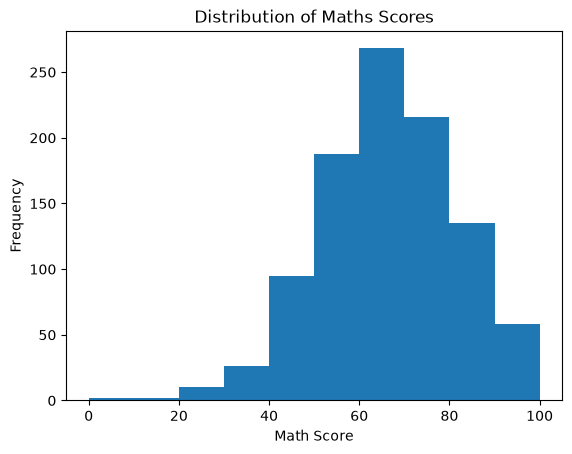

In [63]:
plt.hist(df['math score'], bins=10)
plt.xlabel('Math Score')
plt.ylabel('Frequency')
plt.title('Distribution of Maths Scores')
plt.show()

**Maths Score Distribution — Histogram**

The histogram shows that Maths scores are broadly concentrated between 50 and 80, with the highest frequency occurring around 60–70.

The distribution appears approximately bell-shaped, with a slight negative skew. A few students have relatively low scores, including one observation with a score of zero.

Overall, the distribution is not perfectly normal but shows a broadly unimodal pattern.

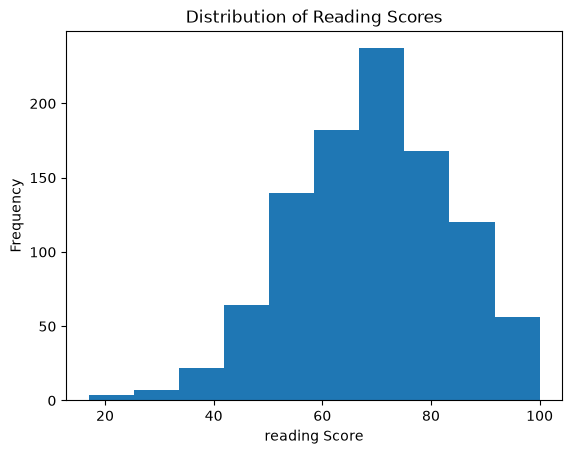

In [65]:
plt.hist(df['reading score'], bins=10)
plt.xlabel('reading Score')
plt.ylabel('Frequency')
plt.title('Distribution of Reading Scores')
plt.show()

**Reading Score Distribution — Histogram**

The histogram shows that Reading scores are mainly concentrated between 50 and 90, with the highest frequency occurring around 65–75.

The distribution is approximately bell-shaped with a slight negative skew. A small number of students have relatively low Reading scores.

Overall, the distribution is broadly unimodal and approximately symmetric, although it is not perfectly normal.

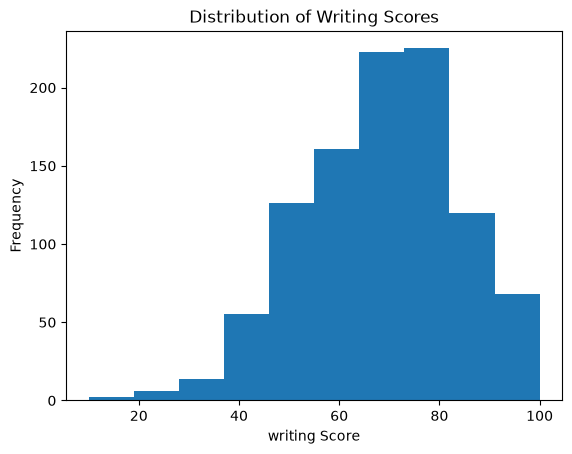

In [66]:
plt.hist(df['writing score'], bins=10)
plt.xlabel('writing Score')
plt.ylabel('Frequency')
plt.title('Distribution of Writing Scores')
plt.show()

**Writing Score Distribution — Histogram**

The histogram shows that Writing scores are mainly concentrated between 50 and 90, with the highest frequency occurring around 70–80.

The distribution is broadly bell-shaped and unimodal, with a slight negative skew. A small number of students have relatively low Writing scores.

Overall, the distribution is approximately symmetric but not perfectly normal.

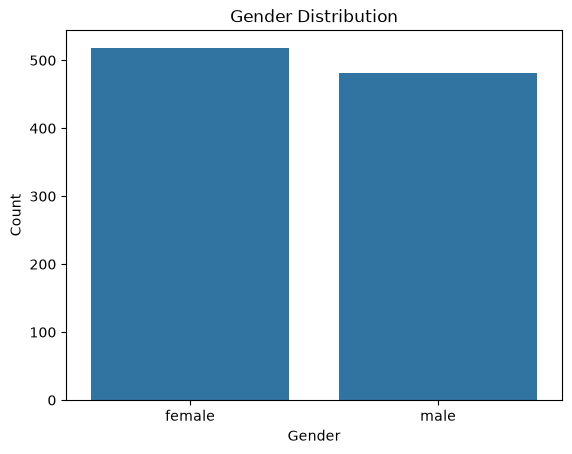

In [67]:
sns.countplot(x='gender', data=df)

plt.xlabel('Gender')
plt.ylabel('Count')
plt.title('Gender Distribution')
plt.show()

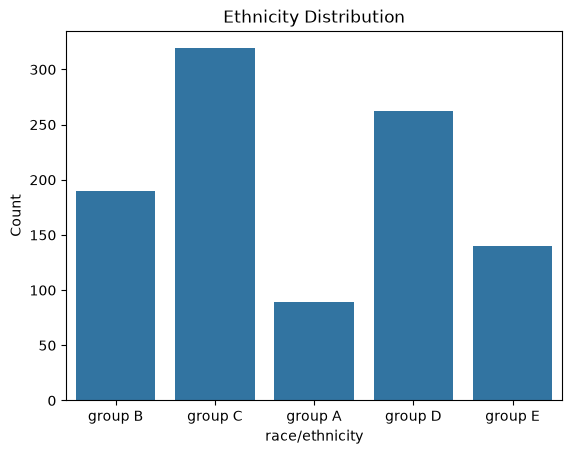

In [68]:
sns.countplot(x='race/ethnicity', data=df)

plt.xlabel('race/ethnicity')
plt.ylabel('Count')
plt.title('Ethnicity Distribution')
plt.show()

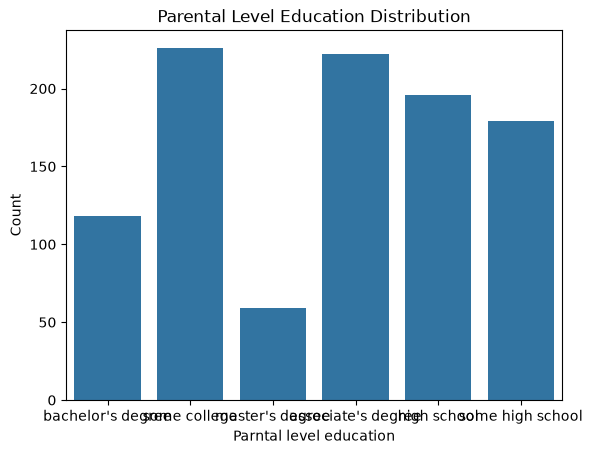

In [69]:
sns.countplot(x='parental level of education', data=df)

plt.xlabel('Parntal level education')
plt.ylabel('Count')
plt.title('Parental Level Education Distribution')
plt.show()

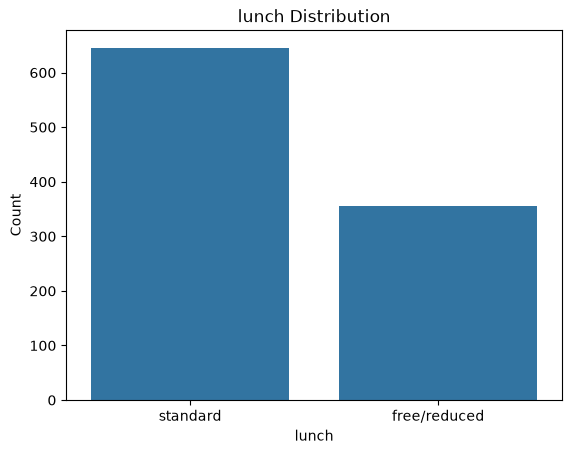

In [70]:
sns.countplot(x='lunch', data=df)

plt.xlabel('lunch')
plt.ylabel('Count')
plt.title('lunch Distribution')
plt.show()

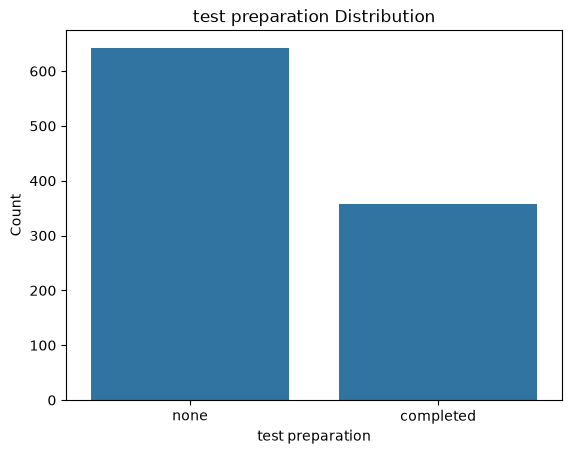

In [71]:
sns.countplot(x='test preparation course' , data = df)
plt.xlabel('test preparation')
plt.ylabel('Count')
plt.title('test preparation Distribution')
plt.show()

<Axes: xlabel='math score', ylabel='gender'>

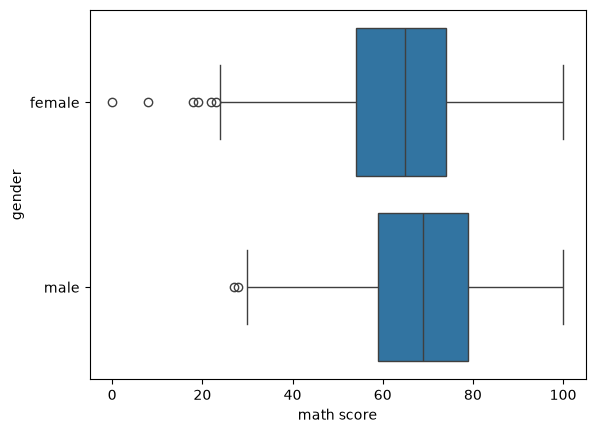

In [6]:
sns.boxplot(data=df , x='math score' , y = 'gender')

<Axes: xlabel='reading score', ylabel='gender'>

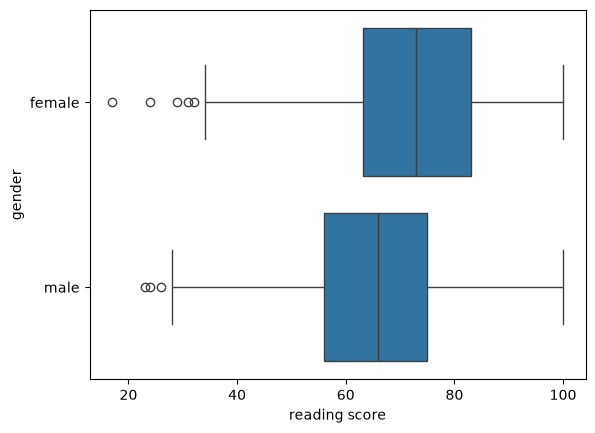

In [7]:
sns.boxplot(data=df , x='reading score' , y = 'gender')

<Axes: xlabel='writing score', ylabel='gender'>

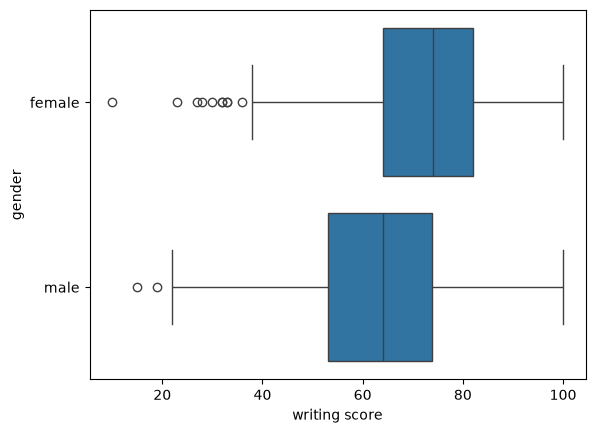

In [8]:
sns.boxplot(data=df , x='writing score' , y = 'gender')

<Axes: xlabel='math score', ylabel='lunch'>

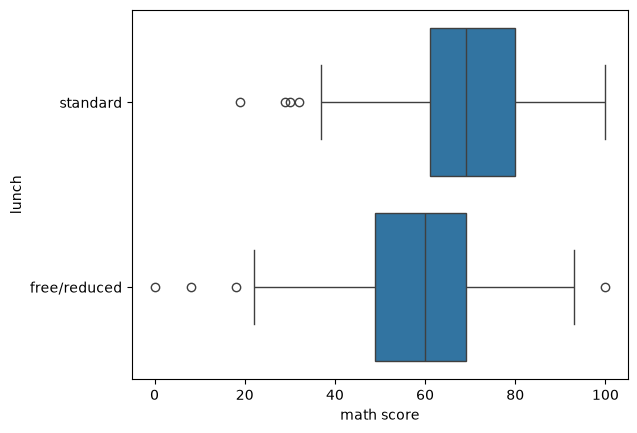

In [9]:
sns.boxplot(data=df , x='math score' , y = 'lunch')

<Axes: xlabel='reading score', ylabel='lunch'>

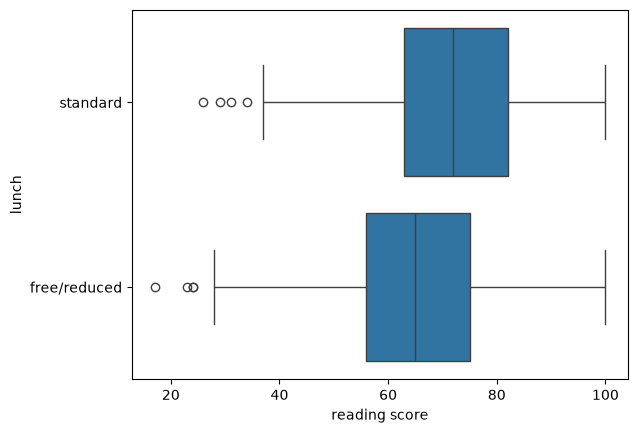

In [11]:
sns.boxplot(data=df , x='reading score' , y = 'lunch')

<Axes: xlabel='writing score', ylabel='lunch'>

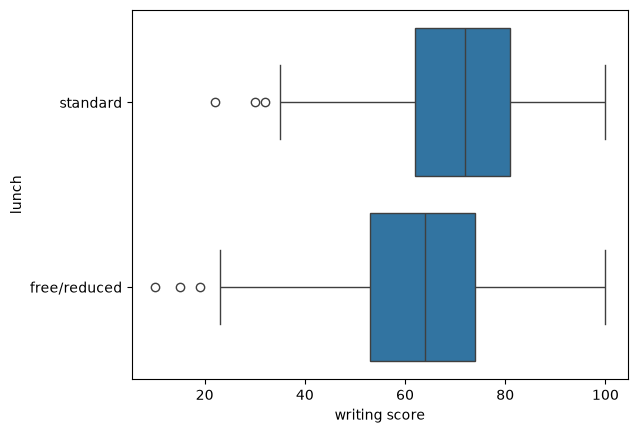

In [10]:
sns.boxplot(data=df , x='writing score' , y = 'lunch')

<Axes: xlabel='math score', ylabel='test preparation course'>

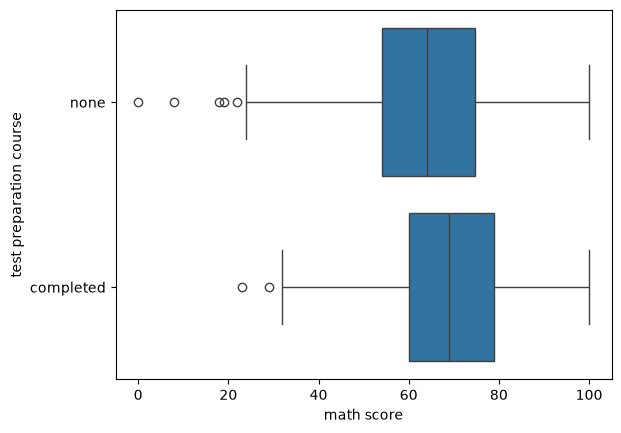

In [12]:
sns.boxplot(data = df , x = 'math score' , y = 'test preparation course')

<Axes: xlabel='reading score', ylabel='test preparation course'>

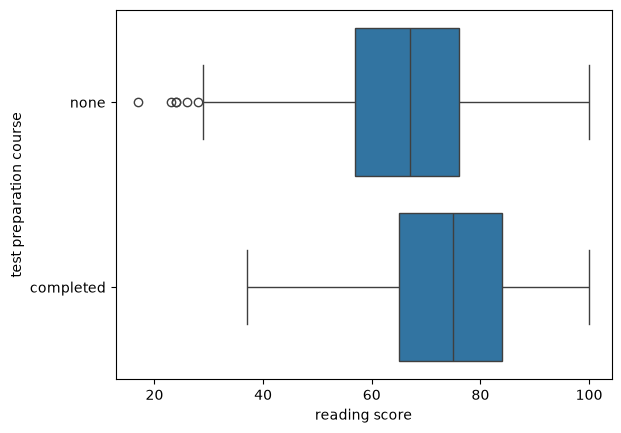

In [13]:
sns.boxplot(data = df , x = 'reading score' , y = 'test preparation course')

<Axes: xlabel='writing score', ylabel='test preparation course'>

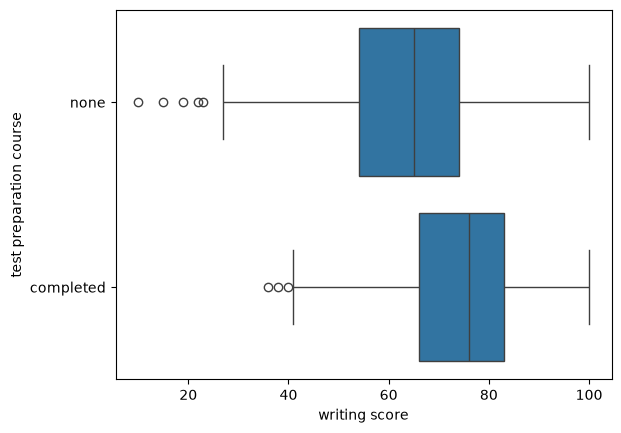

In [14]:
sns.boxplot(data = df , x = 'writing score' , y = 'test preparation course')

<Axes: xlabel='math score', ylabel='parental level of education'>

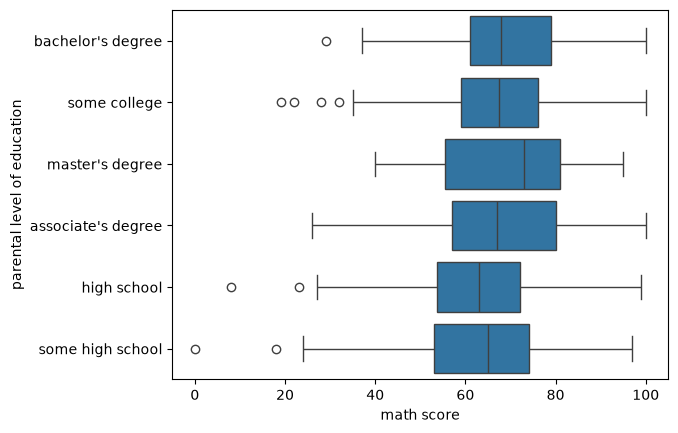

In [17]:
sns.boxplot(data = df , x = 'math score' , y = 'parental level of education')

<Axes: xlabel='writing score', ylabel='parental level of education'>

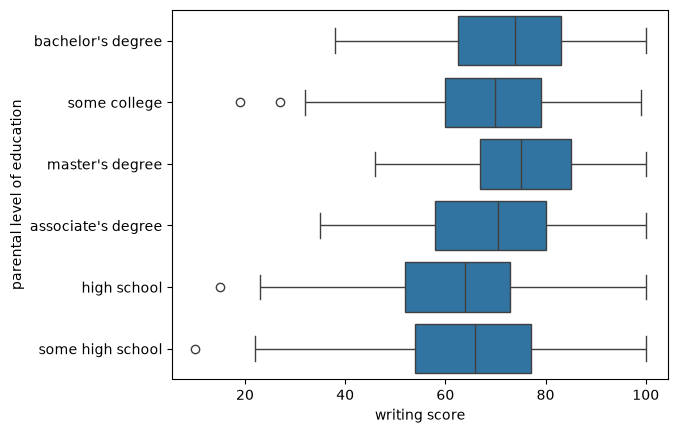

In [16]:
sns.boxplot(data = df , x = 'writing score' , y = 'parental level of education')

<Axes: xlabel='reading score', ylabel='parental level of education'>

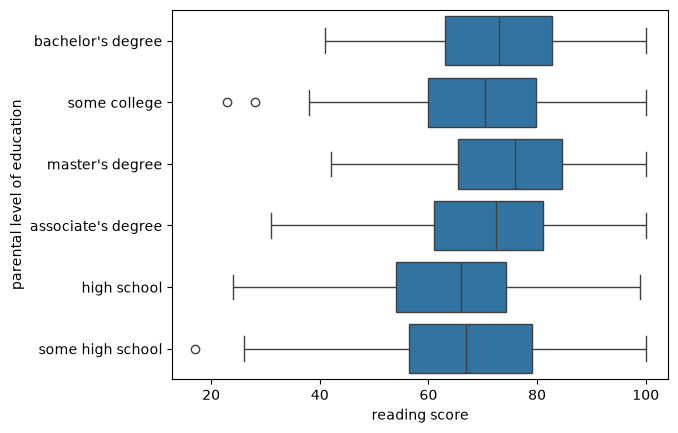

In [15]:
sns.boxplot(data = df , x = 'reading score' , y = 'parental level of education')

<Axes: xlabel='math score', ylabel='reading score'>

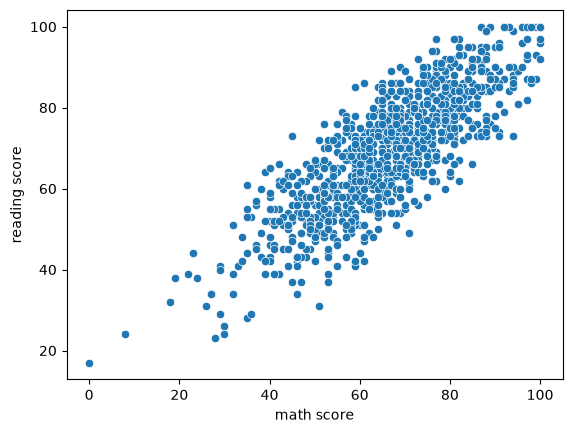

In [18]:
sns.scatterplot(data = df , x = 'math score' , y = 'reading score')

<Axes: xlabel='math score', ylabel='writing score'>

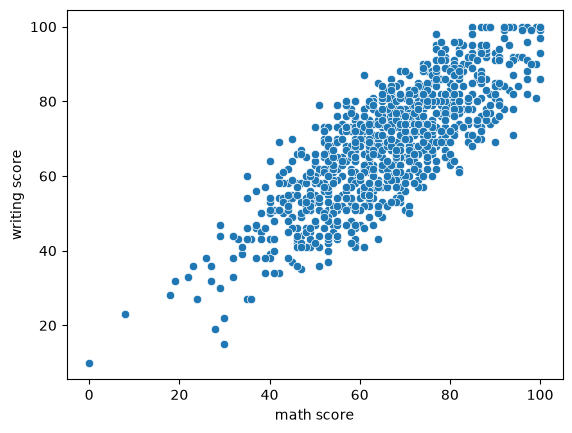

In [19]:
sns.scatterplot(data = df , x = 'math score' , y = 'writing score')

<Axes: xlabel='reading score', ylabel='writing score'>

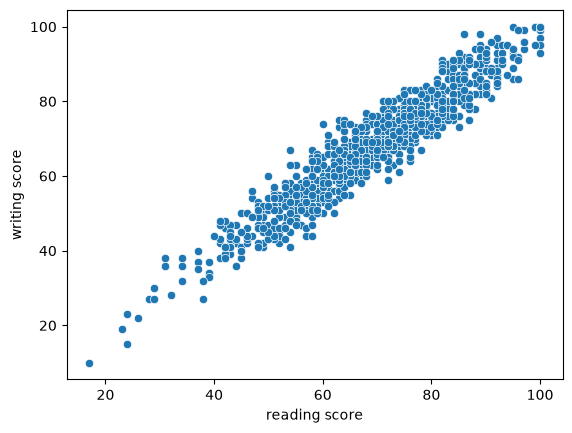

In [21]:
sns.scatterplot(data = df , x = 'reading score' , y = 'writing score')

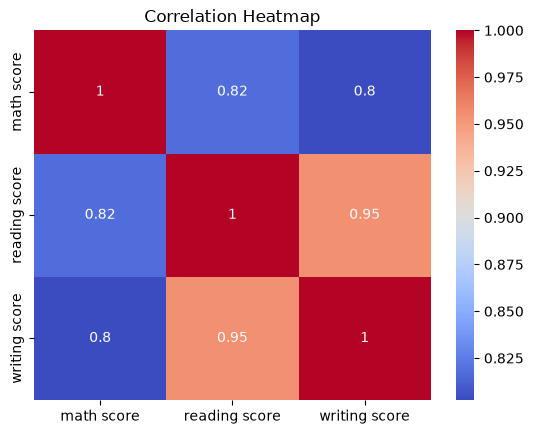

In [22]:
sns.heatmap(
    df[['math score', 'reading score', 'writing score']].corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title('Correlation Heatmap')
plt.show()

## 10. Key Findings

Based on the exploratory data analysis and statistical investigation, the following key findings were identified.

### 1. Dataset Quality
- The dataset contains 1,000 student records and 8 columns.
- No missing values or duplicate records were identified.
- One student had a Maths score of zero. It was retained because there was no evidence that it was invalid.
- A total of 19 subject-level IQR outlier observations were identified across the three score columns. These do not necessarily represent 19 different students.

### 2. Subject Performance
- Average Maths score: 66.09
- Average Reading score: 69.17
- Average Writing score: 68.05
- Reading had the highest average score, followed by Writing and Maths.
- All three score distributions showed mild negative skewness.

### 3. Gender-Based Findings
- Male students had a higher average Maths score.
- Female students had higher average Reading and Writing scores.
- The largest average difference between genders was observed in Writing scores.

### 4. Lunch-Based Findings
- Students in the Standard lunch category had higher average scores in all three subjects than students in the Free/reduced category.
- The largest average difference was observed in Maths scores.

### 5. Test Preparation Findings
- Students who completed the test preparation course had higher average scores in Maths, Reading and Writing.
- The largest average difference was observed in Writing scores.

### 6. Parental Education Findings
- Students whose parents had a Master's degree had the highest average scores across all three subjects.
- Students in the High school parental education category had the lowest average scores across all three subjects.
- These are descriptive comparisons and do not establish that parental education causes differences in student performance.

### 7. Race/Ethnicity Findings
- Group E had the highest average scores across all three subjects.
- Group A had the lowest average scores across all three subjects.
- Group sizes varied, so comparisons should be interpreted with appropriate caution.

### 8. Correlation Findings
All three subjects showed strong positive correlations:

| Subject Pair | Correlation |
|---|---:|
| Maths – Reading | 0.818 |
| Maths – Writing | 0.803 |
| Reading – Writing | 0.955 |

Reading and Writing had the strongest positive correlation.

### 9. Statistical Analysis Findings
- Welch's independent samples t-test identified a statistically significant difference in mean Maths scores between male and female students (p < 0.05).
- Cohen's d was approximately 0.341, indicating a small effect size.
- One-way ANOVA identified statistically significant differences in mean Maths scores across parental education categories (p < 0.05).
- Tukey's HSD identified six statistically significant pairwise differences among the 15 parental education category comparisons.

### Overall Key Insight

Student performance varied across gender, lunch category, test preparation status, parental education and race/ethnicity categories. Reading and Writing scores were particularly strongly associated with each other.

## 11. Conclusion

The objective of this project was to perform Exploratory Data Analysis (EDA) on the Student Performance in Exams dataset to understand student academic performance and investigate relationships between examination scores and demographic or educational factors.

The analysis included data inspection, data quality checks, descriptive statistics, univariate analysis, bivariate analysis, statistical hypothesis testing and data visualization.

The findings showed differences in academic performance across several student categories. Students who completed test preparation had higher average scores across all three subjects, while students in the Standard lunch category also demonstrated higher average scores than those in the Free/reduced category.

The analysis also identified strong positive relationships among Maths, Reading and Writing scores, with the strongest relationship occurring between Reading and Writing.

Statistical testing provided further evidence of differences in Maths scores across gender groups and parental education categories. However, statistical significance and observed associations do not establish causation.

### Limitations

1. The dataset contains limited information about students and their academic backgrounds.
2. The analysis is observational and cannot establish causal relationships.
3. The race/ethnicity categories are anonymized.
4. Statistical hypothesis testing was performed on selected comparisons rather than every possible relationship.
5. The findings may not generalize to all student populations.

### Final Conclusion

This project demonstrates how exploratory data analysis can be used to understand data quality, identify patterns, compare groups, investigate relationships and derive meaningful insights from a real-world dataset.

The project also establishes a foundation for future Machine Learning work, where student performance could be investigated through predictive modelling and feature analysis.